In [8]:
# 2주차 실습: 전처리와 특징 추출 → dataset.npz
# 흐름도: docs/preprocessing.md   /   실행 파일 버전: scripts/preprocessing.py
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, iirnotch, welch

plt.rcParams["font.family"] = "AppleGothic"   # macOS 한글 폰트 (Windows는 "Malgun Gothic")
plt.rcParams["axes.unicode_minus"] = False
FIG_DIR = Path("figures/week_2")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- 단계 0: 시행 1920개 읽기 (1주차 3-1, 3-3과 같은 코드) ----
DATA_DIR = "data/data"
FS = 1000
TRIAL_LEN = 5 * FS
CH_COLS = [f"bandpass {i}" for i in range(1, 6)]
CH_NAMES = CH_COLS   # 그림·특징 이름에도 CSV 열 이름을 그대로 쓴다 (1 요측수근신근, 2 총지신근, 3 천지굴근, 4 상완이두근, 5 상완삼두근)
GESTURES = {"fist": "fist", "open": "open", "pro": "pronation", "extor": "supination"}


def parse_name(path: str) -> tuple[str, int, str]:
    """"data/data/a_30 fist.csv" -> ("a", 30, "fist")"""
    subject, rest = os.path.splitext(os.path.basename(path))[0].split("_")
    angle, gesture = rest.split(" ")
    return subject, int(angle), GESTURES[gesture]


rows, segments = [], []
for f in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    subject, angle, gesture = parse_name(f)
    df = pd.read_csv(f)
    emg = df[CH_COLS].to_numpy(np.float32)
    for rep, s in enumerate(np.flatnonzero(df["mark"].to_numpy() == 1), 1):
        segments.append(emg[s:s + TRIAL_LEN])                         # mark부터 5초
        rows.append({"subject": subject, "angle": angle, "gesture": gesture,
                     "label": f"{angle}_{gesture}", "rep": rep, "start": int(s)})
trial_emg = np.stack(segments)   # (1920, 5000, 5)
trials = pd.DataFrame(rows)      # 시행별 정보 (행 순서가 trial_emg와 짝)
print("시행 배열:", trial_emg.shape, "/ 시행 표:", trials.shape)

시행 배열: (1920, 5000, 5) / 시행 표: (1920, 6)


필터 전 채널별 표준편차: [0.0208 0.0518 0.0377 0.0119 0.0049]
필터 후 채널별 표준편차: [0.0199 0.0501 0.0369 0.0113 0.0044]


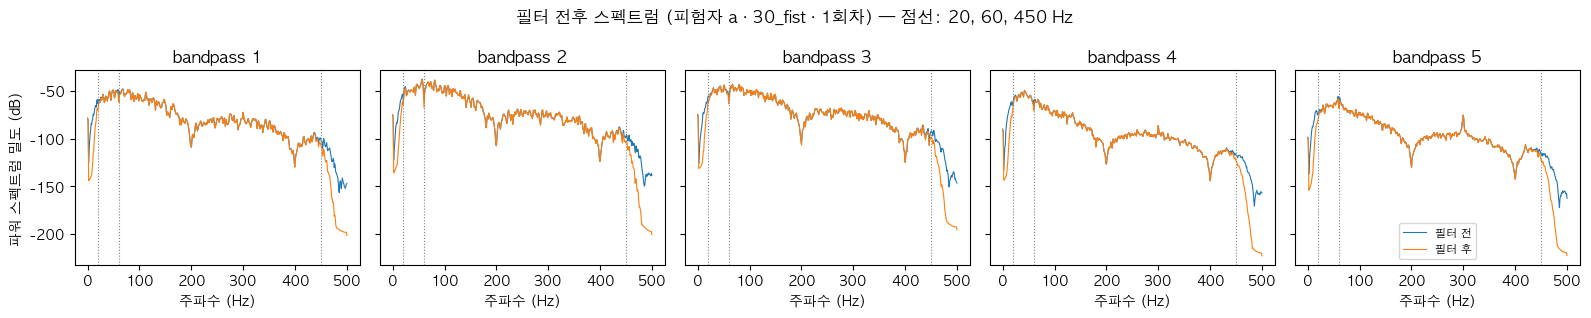

In [9]:
# 실습 단계 1: 필터 적용 (60 Hz 노치 + 20~450 Hz 대역통과)
# 주의: 이 데이터는 열 이름(bandpass 1~5)대로 이미 같은 필터가 걸려 있다 (데이터셋 README).
# 강의 순서대로 한 번 더 걸되, 전후 차이가 작게 나오는 것이 정상 → 제출물 ① 필터 전후 스펙트럼 비교
def preprocess(x: np.ndarray, fs: int = FS) -> np.ndarray:
    """60 Hz 노치 + 20~450 Hz 4차 Butterworth 대역통과. x: (샘플, 채널). filtfilt라 신호가 밀리지 않는다."""
    bn, an = iirnotch(60, 30, fs)                     # Q=30은 실습 설정
    x = filtfilt(bn, an, x, axis=0)
    b, a = butter(4, [20 / (fs / 2), 450 / (fs / 2)], btype="band")
    return filtfilt(b, a, x, axis=0)


i = trials.query("subject == 'a' and label == '30_fist' and rep == 1").index[0]
x = trial_emg[i]
xf = preprocess(x)
print("필터 전 채널별 표준편차:", x.std(0).round(4))
print("필터 후 채널별 표준편차:", xf.std(0).round(4))

f, p_before = welch(x, fs=FS, nperseg=1024, axis=0)
_, p_after = welch(xf, fs=FS, nperseg=1024, axis=0)
fig, ax = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ch in range(5):
    ax[ch].plot(f, 10 * np.log10(p_before[:, ch]), lw=0.8, label="필터 전")
    ax[ch].plot(f, 10 * np.log10(p_after[:, ch]), lw=0.8, label="필터 후")
    for hz in (20, 60, 450):
        ax[ch].axvline(hz, color="gray", ls=":", lw=0.8)
    ax[ch].set_title(CH_NAMES[ch])
    ax[ch].set_xlabel("주파수 (Hz)")
ax[0].set_ylabel("파워 스펙트럼 밀도 (dB)")
ax[-1].legend(fontsize=8)
fig.suptitle("필터 전후 스펙트럼 (피험자 a · 30_fist · 1회차) — 점선: 20, 60, 450 Hz")
plt.tight_layout()
plt.savefig(FIG_DIR / "filter_spectrum.png", dpi=120)
plt.show()

세그먼트 모양: (2000, 5) (1.0~3.0초)


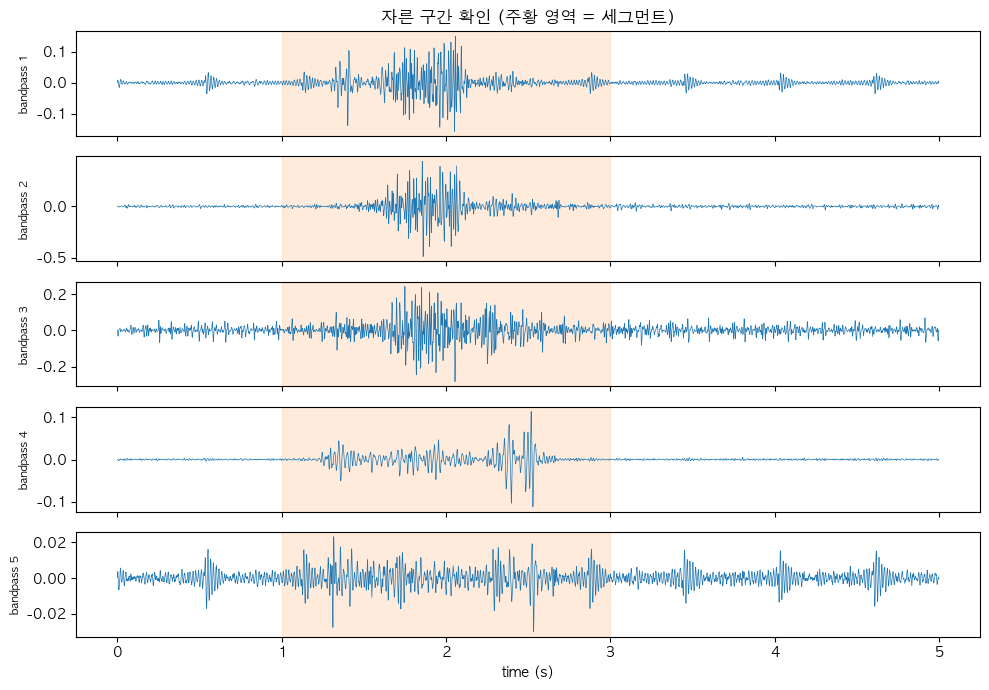

In [10]:
# 실습 단계 2: 분석 구간 잘라내기
# 강의 예시는 START=1500(1.5초)이지만, 1주차 4-2에서 실제 동작 구간이 1.0~2.7초로 확인되어
# START=1000, LEN=2000 (1.0~3.0초)으로 잡았다
START, LEN = 1000, 2000


def cut(x: np.ndarray, start: int = START, n: int = LEN) -> np.ndarray:
    """시행에서 분석 구간만 잘라낸다. (5000, 5) -> (2000, 5)"""
    return x[start:start + n]


seg = cut(xf)
print("세그먼트 모양:", seg.shape, f"({START / FS:.1f}~{(START + LEN) / FS:.1f}초)")

t = np.arange(len(xf)) / FS
fig, ax = plt.subplots(5, 1, figsize=(10, 7), sharex=True)
for ch in range(5):
    ax[ch].plot(t, xf[:, ch], lw=0.5)
    ax[ch].axvspan(START / FS, (START + LEN) / FS, color="C1", alpha=0.15)
    ax[ch].set_ylabel(CH_NAMES[ch], fontsize=8)
ax[0].set_title("자른 구간 확인 (주황 영역 = 세그먼트)")
ax[-1].set_xlabel("time (s)")
plt.tight_layout()
plt.savefig(FIG_DIR / "cut_check.png", dpi=120)
plt.show()

In [11]:
# 실습 단계 3: 슬라이딩 윈도우 (200 ms 창, 100 ms 간격) → 제출물 ② 윈도우 배열 모양
WIN, HOP = 200, 100


def make_windows(x: np.ndarray, win: int = WIN, hop: int = HOP) -> np.ndarray:
    """(2000, 5) -> (19, 200, 5). 창 수 = (len - win) // hop + 1"""
    n = (len(x) - win) // hop + 1
    return np.stack([x[i * hop:i * hop + win] for i in range(n)])


w = make_windows(seg)
print("윈도우 배열:", w.shape, f"= ({LEN} - {WIN}) // {HOP} + 1 = {(LEN - WIN) // HOP + 1}개 창")
print(f"창 1: {START / FS:.1f}~{(START + WIN) / FS:.1f}초 / "
      f"창 2: {(START + HOP) / FS:.1f}~{(START + HOP + WIN) / FS:.1f}초 (절반이 겹침)")

윈도우 배열: (19, 200, 5) = (2000 - 200) // 100 + 1 = 19개 창
창 1: 1.0~1.2초 / 창 2: 1.1~1.3초 (절반이 겹침)


In [12]:
# 실습 단계 4: 시간영역 특징 5종 x 5채널 = 25차원 → 제출물 ③ td_features 함수
FEATURE_NAMES = [f"{f}_{ch}" for f in ("RMS", "MAV", "WL", "ZC", "SSC") for ch in CH_NAMES]


def td_features(w: np.ndarray, th: float = 0.01) -> np.ndarray:
    """창 하나의 시간영역 특징. (200, 5) -> (25,)  순서는 FEATURE_NAMES와 같다"""
    rms = np.sqrt(np.mean(w ** 2, axis=0))                     # 제곱 평균의 제곱근: 신호 세기
    mav = np.mean(np.abs(w), axis=0)                           # 절댓값 평균
    d = np.diff(w, axis=0)
    wl = np.sum(np.abs(d), axis=0)                             # 인접 샘플 차이의 누적: 파형 복잡도
    zc = np.sum(((w[:-1] * w[1:]) < 0) & (np.abs(d) >= th), axis=0)  # 0을 지난 횟수 (작은 흔들림은 무시)
    ssc = np.sum((d[:-1] * d[1:]) < 0, axis=0)                 # 기울기 부호가 바뀐 횟수
    return np.concatenate([rms, mav, wl, zc, ssc])


fv = td_features(w[0])
print("특징 벡터:", fv.shape, "/ NaN 개수:", int(np.isnan(fv).sum()))
print(pd.Series(fv, index=FEATURE_NAMES).round(4).to_string())

# ZC 임계값의 효과: th=0이면 잡음의 미세한 부호 변화까지 세서 값이 커진다
# 단, 이 데이터는 진폭이 작아서(휴식 0.002~0.005, 동작 0.01~0.5) 강의 기본값 th=0.01이 꽤 큰 편이다.
# Biceps·Triceps는 동작 중에도 ZC가 0인 창이 절반쯤 된다 → 3주차에서 th를 낮춘 경우와 성능 비교해 볼 것
print("\nZC (5채널)  th=0.01 vs th=0")
for name, win_ in [("창 1 (동작 시작)", w[0]), ("창 10 (동작 중)", w[9]), ("창 19 (동작 끝)", w[18])]:
    print(f"  {name:12} {td_features(win_, th=0.01)[15:20].astype(int)}  {td_features(win_, th=0)[15:20].astype(int)}")

특징 벡터: (25,) / NaN 개수: 0
RMS_bandpass 1     0.0112
RMS_bandpass 2     0.0071
RMS_bandpass 3     0.0176
RMS_bandpass 4     0.0014
RMS_bandpass 5     0.0053
MAV_bandpass 1     0.0085
MAV_bandpass 2     0.0057
MAV_bandpass 3     0.0124
MAV_bandpass 4     0.0011
MAV_bandpass 5     0.0040
WL_bandpass 1      0.6664
WL_bandpass 2      0.4799
WL_bandpass 3      1.3162
WL_bandpass 4      0.0916
WL_bandpass 5      0.3099
ZC_bandpass 1      3.0000
ZC_bandpass 2      0.0000
ZC_bandpass 3     12.0000
ZC_bandpass 4      0.0000
ZC_bandpass 5      0.0000
SSC_bandpass 1    27.0000
SSC_bandpass 2    39.0000
SSC_bandpass 3    43.0000
SSC_bandpass 4    56.0000
SSC_bandpass 5    29.0000

ZC (5채널)  th=0.01 vs th=0
  창 1 (동작 시작)  [ 3  0 12  0  0]  [26 28 33 26 23]
  창 10 (동작 중)  [27 27 30  2  0]  [28 28 30 18 26]
  창 19 (동작 끝)  [ 4  4 11  0  0]  [22 29 29 27 23]


In [23]:
# 실습 단계 5: 데이터셋 만들기 — 누수 막기 → 제출물 ④ 분할 코드
# (1) 시행 단위로 먼저 나눈다. 같은 시행의 창 19개는 서로 겹치므로,
#     창을 만든 뒤에 나누면 한 시행의 조각이 학습과 테스트 양쪽에 들어간다 (데이터 누수)
# 강의 예시는 파일(files) 단위로 나누지만, 이 데이터는 파일 하나에 30회가 있어 trials의 행 번호(시행)로 나눈다
from sklearn.model_selection import train_test_split

idx_tr, idx_te = train_test_split(trials.index.to_numpy(), test_size=0.2,
                                  stratify=trials["label"], random_state=42)
assert not set(idx_tr) & set(idx_te)   # 겹치는 시행이 없어야 한다
print("학습 시행:", len(idx_tr), "/ 테스트 시행:", len(idx_te))


# (2) 각 집합 안에서만 필터 → 자르기 → 윈도우 → 특징
def build(idx: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """시행 번호 목록 -> X (시행 수x19, 25), y (창마다의 라벨), g (창이 온 시행 번호)"""
    X, y, g = [], [], []
    for i in idx:
        for wnd in make_windows(cut(preprocess(trial_emg[i]))):
            if not X:
                print(i)
                print(wnd.shape)
            X.append(td_features(wnd))
            y.append(trials.loc[i, "label"])
            g.append(i)
    return np.stack(X), np.array(y), np.array(g)


Xtr, ytr, gtr = build(idx_tr)
Xte, yte, gte = build(idx_te)
print("Xtr:", Xtr.shape, "/ Xte:", Xte.shape, "(창 수, 25차원)")
print("학습 창 수 / 테스트 창 수 =", round(len(Xtr) / len(Xte), 2), "(약 4배면 정상)")

# 제출물 ⑤ 데이터셋 요약: 클래스별 창 수
summary = pd.DataFrame({"학습": pd.Series(ytr).value_counts(),
                        "테스트": pd.Series(yte).value_counts()}).sort_index()
summary.loc["합계"] = summary.sum()
summary

학습 시행: 1536 / 테스트 시행: 384
1442
(200, 5)
1270
(200, 5)
Xtr: (29184, 25) / Xte: (7296, 25) (창 수, 25차원)
학습 창 수 / 테스트 창 수 = 4.0 (약 4배면 정상)


,학습,테스트
30_fist,3648,912
30_open,3648,912
30_pronation,3648,912
30_supination,3648,912
60_fist,3648,912
60_open,3648,912
60_pronation,3648,912
60_supination,3648,912
합계,29184,7296


In [14]:
# 실습 단계 6: 표준화와 저장
# 평균·표준편차는 학습셋에서만 계산(fit)하고, 테스트셋에는 그 값을 적용(transform)만 한다
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
Xtr_s = sc.fit_transform(Xtr)
Xte_s = sc.transform(Xte)
print("학습셋  평균 (최대 절댓값):", np.abs(Xtr_s.mean(0)).max().round(6),
      "/ 표준편차:", Xtr_s.std(0).min().round(3), "~", Xtr_s.std(0).max().round(3))
print("테스트셋 평균 범위:", Xte_s.mean(0).min().round(2), "~", Xte_s.mean(0).max().round(2),
      "(정확히 0·1이 아니어도 정상)")

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
path = OUT / "dataset.npz"
np.savez(path,
         Xtr=Xtr_s.astype(np.float32), ytr=ytr, gtr=gtr,
         Xte=Xte_s.astype(np.float32), yte=yte, gte=gte,
         subject_tr=trials.loc[gtr, "subject"].to_numpy().astype(str),   # object 배열은 np.load가 거부한다
         subject_te=trials.loc[gte, "subject"].to_numpy().astype(str),
         feature_names=np.array(FEATURE_NAMES))
print("저장 완료:", path, f"({path.stat().st_size / 1e6:.1f} MB)")

학습셋  평균 (최대 절댓값): 0.0 / 표준편차: 1.0 ~ 1.0
테스트셋 평균 범위: -0.05 ~ 0.08 (정확히 0·1이 아니어도 정상)
저장 완료: outputs/dataset.npz (6.0 MB)


In [15]:
# 저장 확인: 3주차는 이 파일에서 시작한다
# gtr/gte(시행 번호)와 subject_tr/te(피험자)는 3주차 교차검증에서 같은 시행·피험자가 갈라지지 않게 묶는 데 쓴다
d = np.load(OUT / "dataset.npz")
{k: (d[k].shape, d[k].dtype.name) for k in d.files}

{'Xtr': ((29184, 25), 'float32'),
 'ytr': ((29184,), 'str416'),
 'gtr': ((29184,), 'int64'),
 'Xte': ((7296, 25), 'float32'),
 'yte': ((7296,), 'str416'),
 'gte': ((7296,), 'int64'),
 'subject_tr': ((29184,), 'str32'),
 'subject_te': ((7296,), 'str32'),
 'feature_names': ((25,), 'str448')}